## **Task 1 - Sentiment Analysis - RNN models**

In [2]:
# Task 1: Sentiment Analysis on IMDB Reviews using Different RNN Architectures

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Bidirectional, Dense, GRU

# Load IMDB datasets
vocab_size = 10000
maxlen = 200
(x_train,y_train),(x_test,y_test) = imdb.load_data(num_words=vocab_size)

# Pad Sequences
x_train = pad_sequences(x_train,maxlen=maxlen)
x_test = pad_sequences(x_test,maxlen=maxlen)

# Model builder function
def build_model(network_layer):
  model = Sequential([
      Embedding(vocab_size,64,input_length=maxlen),
      network_layer,
      Dense(1,activation='sigmoid')
  ])
  model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
  return model

# 1. Simple RNN
simple_rnn_model = build_model(SimpleRNN(64))
simple_rnn_model.summary()
simple_rnn_model.fit(x_train,y_train,epochs=1,validation_split=0.2,batch_size=128)

# 2. LSTM
lstm_model = build_model(LSTM(64))
lstm_model.summary()
lstm_model.fit(x_train, y_train, epochs=3, validation_split=0.2, batch_size=128)

# 3. Bidirectional LSTM
bilstm_model = build_model(Bidirectional(LSTM(64)))
bilstm_model.summary()
bilstm_model.fit(x_train, y_train, epochs=1, validation_split=0.2, batch_size=128)

# 4. Stacked LSTM
stacked_lstm_model = Sequential([
    Embedding(vocab_size, 64, input_length=maxlen),
    LSTM(64, return_sequences=True),
    LSTM(32),
    Dense(1, activation='sigmoid')
])
stacked_lstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
stacked_lstm_model.summary()
stacked_lstm_model.fit(x_train, y_train, epochs=1, validation_split=0.2, batch_size=128)

# 5. GRU
gru_model = build_model(GRU(64))
gru_model.summary()
gru_model.fit(x_train, y_train, epochs=1, validation_split=0.2, batch_size=128)

# Evaluate all models
def evaluate_model(model, name):
    loss, acc = model.evaluate(x_test, y_test)
    print(f"{name} Accuracy: {acc:.4f}, Loss: {loss:.4f}")

evaluate_model(simple_rnn_model, "Simple RNN")
evaluate_model(lstm_model, "LSTM")
evaluate_model(bilstm_model, "Bidirectional LSTM")
evaluate_model(stacked_lstm_model, "Stacked LSTM")
evaluate_model(gru_model, "GRU")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

157/157 ━━━━━━━━━━━━━━━━━━━━ 66s 407ms/step - accuracy: 0.7401 - loss: 0.5045 - val_accuracy: 0.8506 - val_loss: 0.3531
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.7560 - loss: 0.5056
Simple RNN Accuracy: 0.7560, Loss: 0.5056
782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.8638 - loss: 0.3609
LSTM Accuracy: 0.8638, Loss: 0.3609
782/782 ━━━━━━━━━━━━━━━━━━━━ 39s 50ms/step - accuracy: 0.8108 - loss: 0.4392
Bidirectional LSTM Accuracy: 0.8108, Loss: 0.4392
782/782 ━━━━━━━━━━━━━━━━━━━━ 39s 49ms/step - accuracy: 0.8648 - loss: 0.3248
Stacked LSTM Accuracy: 0.8648, Loss: 0.3248
782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.8469 - loss: 0.3549
GRU Accuracy: 0.8469, Loss: 0.3549


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 105ms/step - accuracy: 0.6039 - loss: 0.6459 - val_accuracy: 0.6740 - val_loss: 0.5910
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 104ms/step - accuracy: 0.8370 - loss: 0.3794 - val_accuracy: 0.7968 - val_loss: 0.4530
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - accuracy: 0.9244 - loss: 0.1952 - val_accuracy: 0.8166 - val_loss: 0.4466


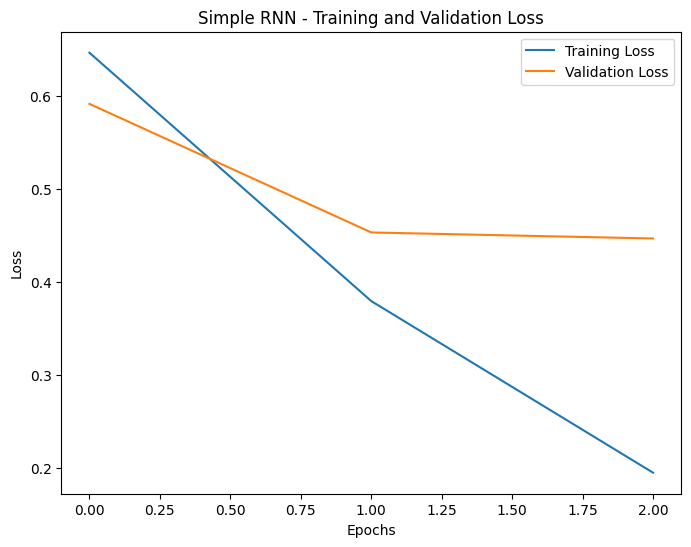

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 354ms/step - accuracy: 0.7736 - loss: 0.4639 - val_accuracy: 0.8518 - val_loss: 0.3481
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 350ms/step - accuracy: 0.9025 - loss: 0.2512 - val_accuracy: 0.8730 - val_loss: 0.2995
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 350ms/step - accuracy: 0.9226 - loss: 0.2088 - val_accuracy: 0.8738 - val_loss: 0.3177


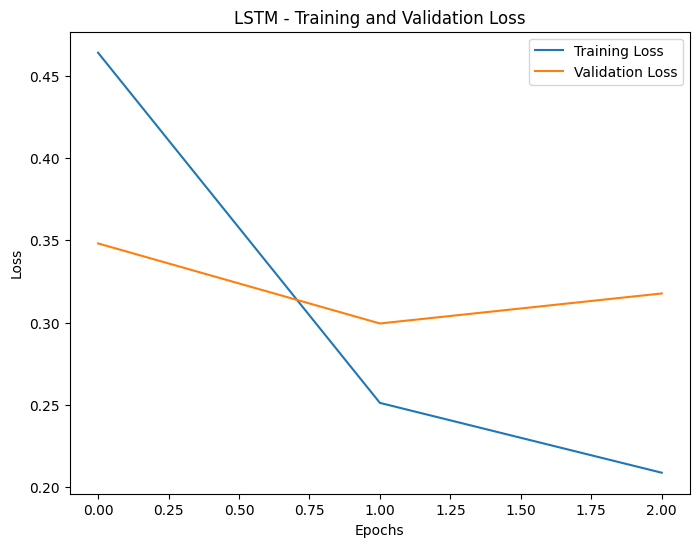

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 100s 617ms/step - accuracy: 0.7668 - loss: 0.4746 - val_accuracy: 0.8442 - val_loss: 0.3581
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 101s 644ms/step - accuracy: 0.8975 - loss: 0.2624 - val_accuracy: 0.8620 - val_loss: 0.3512
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 97s 621ms/step - accuracy: 0.9276 - loss: 0.1955 - val_accuracy: 0.8738 - val_loss: 0.3099


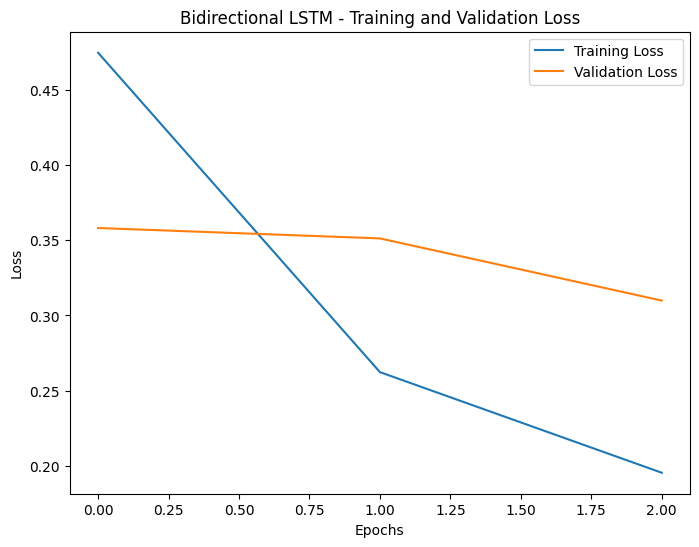

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 86s 525ms/step - accuracy: 0.7867 - loss: 0.4371 - val_accuracy: 0.8640 - val_loss: 0.3270
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 77s 489ms/step - accuracy: 0.9081 - loss: 0.2409 - val_accuracy: 0.8704 - val_loss: 0.3000
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 76s 485ms/step - accuracy: 0.9370 - loss: 0.1762 - val_accuracy: 0.8728 - val_loss: 0.3427


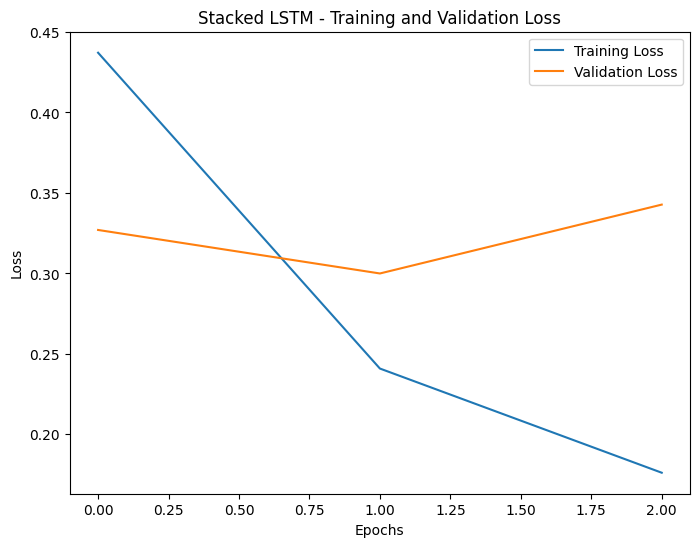

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 66s 403ms/step - accuracy: 0.7333 - loss: 0.5080 - val_accuracy: 0.8464 - val_loss: 0.3579
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 402ms/step - accuracy: 0.8918 - loss: 0.2708 - val_accuracy: 0.8566 - val_loss: 0.3658
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 62s 397ms/step - accuracy: 0.9196 - loss: 0.2082 - val_accuracy: 0.8678 - val_loss: 0.3269


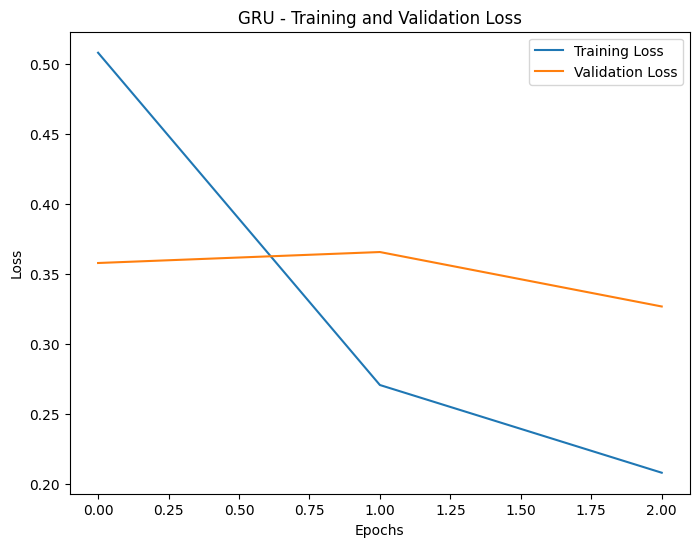

782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8138 - loss: 0.4598
Simple RNN Accuracy: 0.8138, Loss: 0.4598
782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step - accuracy: 0.8612 - loss: 0.3461
LSTM Accuracy: 0.8612, Loss: 0.3461
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.8669 - loss: 0.3320
Bidirectional LSTM Accuracy: 0.8669, Loss: 0.3320
782/782 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.8612 - loss: 0.3707
Stacked LSTM Accuracy: 0.8612, Loss: 0.3707
782/782 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.8632 - loss: 0.3424
GRU Accuracy: 0.8632, Loss: 0.3424

Predictions on New Text:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
Simple RNN: Negative
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
LSTM: Positive
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step
Bidirectional LSTM: Negative
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step
Stacked LSTM: Positive


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step
GRU: Positive


In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Bidirectional, Dense, GRU
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Load IMDB dataset
vocab_size = 10000  # Top 10,000 words
maxlen = 200  # Max review length
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

# Pad sequences
x_train = pad_sequences(x_train, maxlen=maxlen)
x_test = pad_sequences(x_test, maxlen=maxlen)

# Initialize tokenizer and fit on training data
tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts([i for i in imdb.get_word_index().keys()])  # Fit tokenizer on IMDB dataset

# Define model builder function
def build_model(rnn_layer):
    model = Sequential([
        Embedding(vocab_size, 64, input_length=maxlen),
        rnn_layer,
        Dense(1, activation='sigmoid')
    ])
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# Function to plot training and validation loss
def plot_loss(history, model_name):
    plt.figure(figsize=(8, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{model_name} - Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

# Function to make predictions on new text
def predict_new_text(model, text, tokenizer, maxlen=200):
    # Preprocess text: Tokenize and pad the sequence
    tokenized_text = tokenizer.texts_to_sequences([text])  # Tokenize the new text
    if not tokenized_text[0]:  # Check if the text is empty after tokenization
        return "Invalid input text."
    padded_text = pad_sequences(tokenized_text, maxlen=maxlen, padding='post')  # Pad the sequence
    prediction = model.predict(padded_text)  # Get prediction
    return "Positive" if prediction >= 0.5 else "Negative"
# 1. Simple RNN
simple_rnn_model = build_model(SimpleRNN(64))
simple_rnn_history = simple_rnn_model.fit(x_train, y_train, epochs=3, validation_split=0.2, batch_size=128)
plot_loss(simple_rnn_history, "Simple RNN")

# 2. LSTM
lstm_model = build_model(LSTM(64))
lstm_history = lstm_model.fit(x_train, y_train, epochs=3, validation_split=0.2, batch_size=128)
plot_loss(lstm_history, "LSTM")

# 3. Bidirectional LSTM
bilstm_model = build_model(Bidirectional(LSTM(64)))
bilstm_history = bilstm_model.fit(x_train, y_train, epochs=3, validation_split=0.2, batch_size=128)
plot_loss(bilstm_history, "Bidirectional LSTM")

# 4. Stacked LSTM
stacked_lstm_model = Sequential([
    Embedding(vocab_size, 64, input_length=maxlen),
    LSTM(64, return_sequences=True),
    LSTM(32),
    Dense(1, activation='sigmoid')
])
stacked_lstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
stacked_lstm_history = stacked_lstm_model.fit(x_train, y_train, epochs=3, validation_split=0.2, batch_size=128)
plot_loss(stacked_lstm_history, "Stacked LSTM")

# 5. GRU
gru_model = build_model(GRU(64))
gru_history = gru_model.fit(x_train, y_train, epochs=3, validation_split=0.2, batch_size=128)
plot_loss(gru_history, "GRU")

# Evaluate all models
def evaluate_model(model, name):
    loss, acc = model.evaluate(x_test, y_test)
    print(f"{name} Accuracy: {acc:.4f}, Loss: {loss:.4f}")

evaluate_model(simple_rnn_model, "Simple RNN")
evaluate_model(lstm_model, "LSTM")
evaluate_model(bilstm_model, "Bidirectional LSTM")
evaluate_model(stacked_lstm_model, "Stacked LSTM")
evaluate_model(gru_model, "GRU")

# Predict on new text using all models
new_text = "I loved the movie, it was fantastic and thrilling!"

print("\nPredictions on New Text:")
print(f"Simple RNN: {predict_new_text(simple_rnn_model, new_text, tokenizer)}")
print(f"LSTM: {predict_new_text(lstm_model, new_text, tokenizer)}")
print(f"Bidirectional LSTM: {predict_new_text(bilstm_model, new_text, tokenizer)}")
print(f"Stacked LSTM: {predict_new_text(stacked_lstm_model, new_text, tokenizer)}")
print(f"GRU: {predict_new_text(gru_model, new_text, tokenizer)}")